<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6754 entries, 0 to 6753
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Story_ID          6754 non-null   object        
 1   Release_ID        6754 non-null   object        
 2   Release_Name      6754 non-null   object        
 3   Epic              6754 non-null   object        
 4   Feature_Name      6754 non-null   object        
 5   Feature_Size      6754 non-null   object        
 6   Story_Name        6754 non-null   object        
 7   Item_Type         6754 non-null   object        
 8   Platform          6740 non-null   object        
 9   Team_ID           6754 non-null   object        
 10  Team_Type         6754 non-null   object        
 11  Team_Size         6754 non-null   int64         
 12  Team_Location     6754 non-null   object        
 13  Story_Points      6754 non-null   int64         
 14  Sprint_Number     6754 n

Story_ID              0
Release_ID            0
Release_Name          0
Epic                  0
Feature_Name          0
Feature_Size          0
Story_Name            0
Item_Type             0
Platform             14
Team_ID               0
Team_Type             0
Team_Size             0
Team_Location         0
Story_Points          0
Sprint_Number         0
Sprint_Start          0
Sprint_End            0
Original_Est_Hrs      0
Bug_Rework_Hrs       25
Actual_Hrs          370
Overrun_Pct         370
N_Tasks               0
Has_QA_Task           0
Status                0
dtype: int64

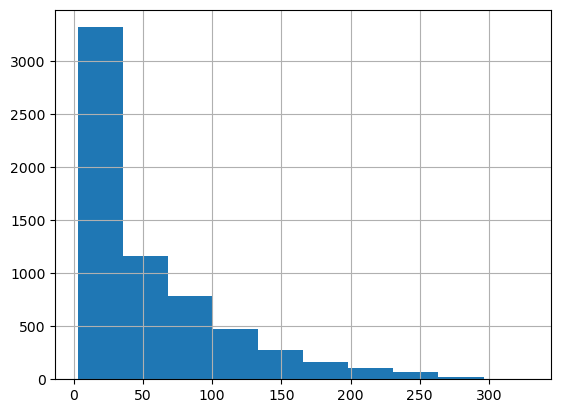

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

stories = pd.read_excel("Fiserv_Dataset.xlsx", sheet_name="User_Stories")
tasks   = pd.read_excel("Fiserv_Dataset.xlsx", sheet_name="Tasks")

stories.info()          # see column types and missing counts
stories.describe()      # distributions of numeric columns
stories["Actual_Hrs"].hist()   # is the target skewed? (it will be)
stories.isnull().sum()  # which columns have missing values

In [2]:
import pandas as pd
check = pd.read_excel("Fiserv_Dataset.xlsx", sheet_name="User_Stories")
print(f"Rows: {len(check)}")

Rows: 6754


### ⚠️ Data generation — DO NOT RUN (one-time only)

This cell originally **expanded the dataset** (added synthetic rows) and **saved** it back to `Fiserv_Dataset.xlsx`.
It has already been run to produce the final frozen dataset and must **not** be run again — re-running compounds the data (rows grow, statistics drift).

The original code is preserved below for reference only:

```python
# (data-generation code — disabled; see Fiserv_Dataset_FROZEN.xlsx for the final data)
```

### ⚠️ Overrun adjustment — DO NOT RUN (one-time only)

This cell originally re-balanced the overrun rate and **saved** back to `Fiserv_Dataset.xlsx`.
Disabled to keep the dataset frozen and reproducible. Reference only.

### ⚠️ Actual-hours calibration — DO NOT RUN (one-time only)

This cell originally re-scaled `Actual_Hrs` per story point and **saved** back to `Fiserv_Dataset.xlsx`.
Disabled to keep the dataset frozen. Reference only.

In [3]:
df = stories.dropna(subset=["Actual_Hrs"]).copy()
df["Bug_Rework_Hrs"] = df["Bug_Rework_Hrs"].fillna(0)
df["Item_Type_enc"]    = df["Item_Type"].map({"Feature":0,"Enhancement":1,"Defect":2})
df["Platform_enc"]     = df["Platform"].map({"iOS":0,"Android":1,"Platform":2})
df["Feature_Size_enc"] = df["Feature_Size"].map({"S":1,"M":2,"L":3})
df["Has_QA_enc"]       = (df["Has_QA_Task"] == "Yes").astype(int)
df["Team_Type_enc"]    = (df["Team_Type"] == "Scrum").astype(int)

In [4]:
# Sort by sprint number (proxy for time)
df = df.sort_values("Sprint_Number") #Sorts all rows from earliest to latest sprint (time order)

# 80% train, 20% test — keeping time order
split = int(len(df) * 0.80)
train = df.iloc[:split]
test  = df.iloc[split:]

In [5]:
# Fix the 14 missing Platform values created during encoding
df["Platform_enc"] = df["Platform_enc"].fillna(df["Platform_enc"].mode()[0])

# Confirm no NaN values remain in any encoded column
encoded_cols = ["Item_Type_enc", "Platform_enc", "Feature_Size_enc", 
                "Has_QA_enc", "Team_Type_enc"]

print("Missing values in encoded columns:")
print(df[encoded_cols].isnull().sum())
print("\nAll zeros = ready to go ✓")

Missing values in encoded columns:
Item_Type_enc       0
Platform_enc        0
Feature_Size_enc    0
Has_QA_enc          0
Team_Type_enc       0
dtype: int64

All zeros = ready to go ✓


In [6]:
from sklearn.model_selection import train_test_split
print(f"Total stories after dropping missing target: {len(df)}")
print(f"Training rows: {len(train)}")
print(f"Test rows:     {len(test)}")
print(f"\nColumns: {list(df.columns)}")

Total stories after dropping missing target: 6384
Training rows: 5107
Test rows:     1277

Columns: ['Story_ID', 'Release_ID', 'Release_Name', 'Epic', 'Feature_Name', 'Feature_Size', 'Story_Name', 'Item_Type', 'Platform', 'Team_ID', 'Team_Type', 'Team_Size', 'Team_Location', 'Story_Points', 'Sprint_Number', 'Sprint_Start', 'Sprint_End', 'Original_Est_Hrs', 'Bug_Rework_Hrs', 'Actual_Hrs', 'Overrun_Pct', 'N_Tasks', 'Has_QA_Task', 'Status', 'Item_Type_enc', 'Platform_enc', 'Feature_Size_enc', 'Has_QA_enc', 'Team_Type_enc']


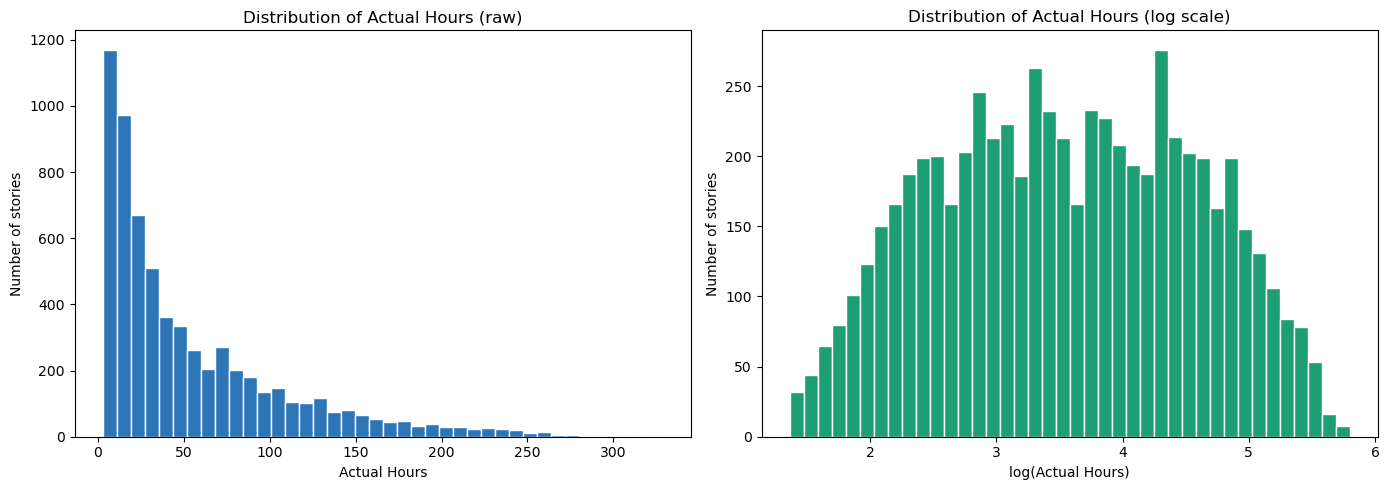

count    6384.0
mean       54.7
std        54.9
min         2.9
25%        14.5
50%        33.0
75%        77.1
max       328.7
Name: Actual_Hrs, dtype: float64


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: raw distribution
axes[0].hist(df["Actual_Hrs"], bins=40, color="#2E75B6", edgecolor="white")
axes[0].set_title("Distribution of Actual Hours (raw)")
axes[0].set_xlabel("Actual Hours")
axes[0].set_ylabel("Number of stories")

# Right: log scale (easier to read skewed data)
import numpy as np
axes[1].hist(np.log1p(df["Actual_Hrs"]), bins=40, color="#1D9E75", edgecolor="white")
axes[1].set_title("Distribution of Actual Hours (log scale)")
axes[1].set_xlabel("log(Actual Hours)")
axes[1].set_ylabel("Number of stories")

plt.tight_layout()
plt.show()

print(df["Actual_Hrs"].describe().round(1))

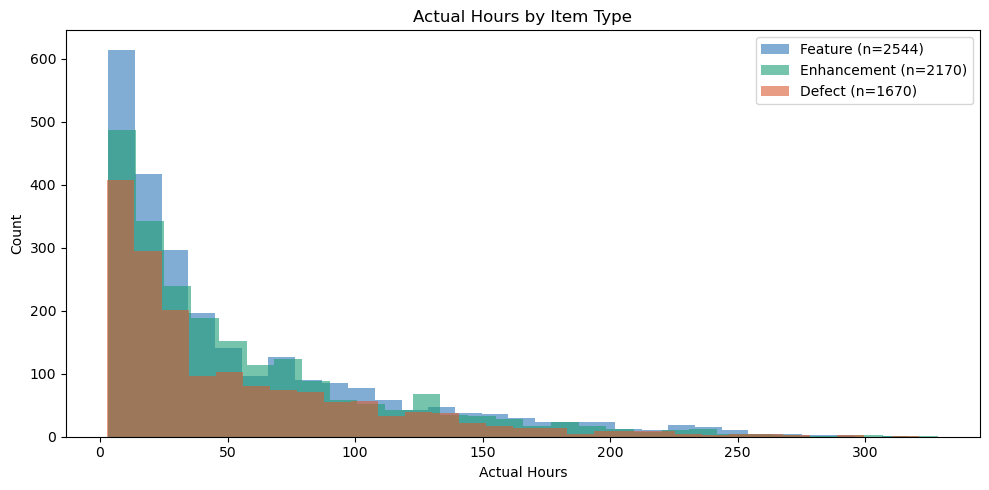

             mean  median  count
Item_Type                       
Defect       52.2    30.2   1670
Enhancement  55.7    36.8   2170
Feature      55.4    32.2   2544


In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

order = ["Feature", "Enhancement", "Defect"]
colors = ["#2E75B6", "#1D9E75", "#D85A30"]

for i, (item_type, color) in enumerate(zip(order, colors)):
    subset = df[df["Item_Type"] == item_type]["Actual_Hrs"]
    ax.hist(subset, bins=30, alpha=0.6, label=f"{item_type} (n={len(subset)})", color=color)

ax.set_title("Actual Hours by Item Type")
ax.set_xlabel("Actual Hours")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

# Print the average for each type
print(df.groupby("Item_Type")["Actual_Hrs"].agg(["mean","median","count"]).round(1))

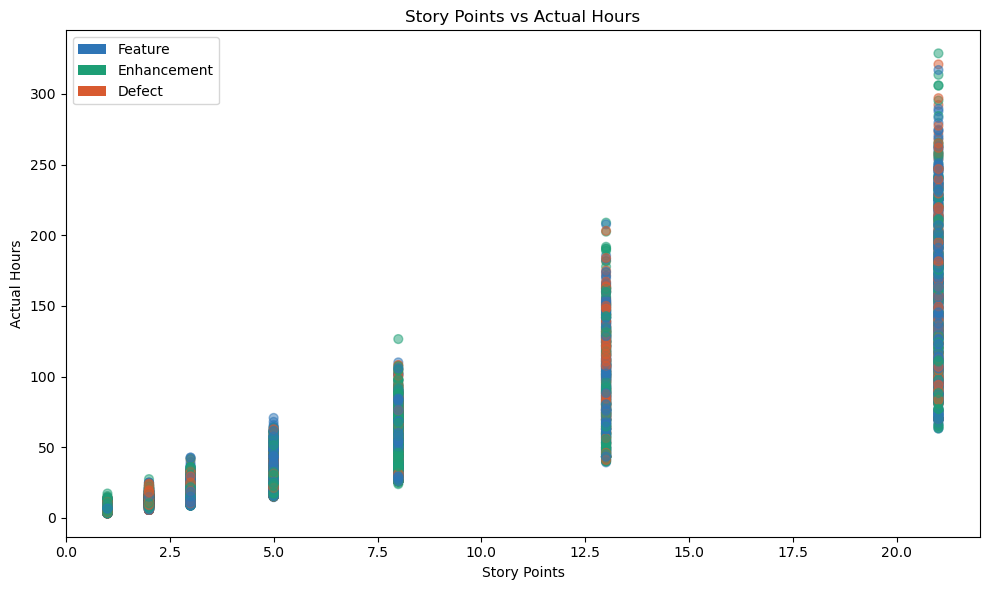

Correlation between Story Points and Actual Hours: 0.88


In [9]:
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    df["Story_Points"],
    df["Actual_Hrs"],
    c=df["Item_Type"].map({"Feature": "#2E75B6", "Enhancement": "#1D9E75", "Defect": "#D85A30"}),
    alpha=0.5,
    s=40
)

ax.set_title("Story Points vs Actual Hours")
ax.set_xlabel("Story Points")
ax.set_ylabel("Actual Hours")

# Add a legend manually
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#2E75B6", label="Feature"),
    Patch(facecolor="#1D9E75", label="Enhancement"),
    Patch(facecolor="#D85A30", label="Defect"),
]
ax.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

# Correlation between story points and actual hours
corr = df["Story_Points"].corr(df["Actual_Hrs"])
print(f"Correlation between Story Points and Actual Hours: {corr:.2f}")

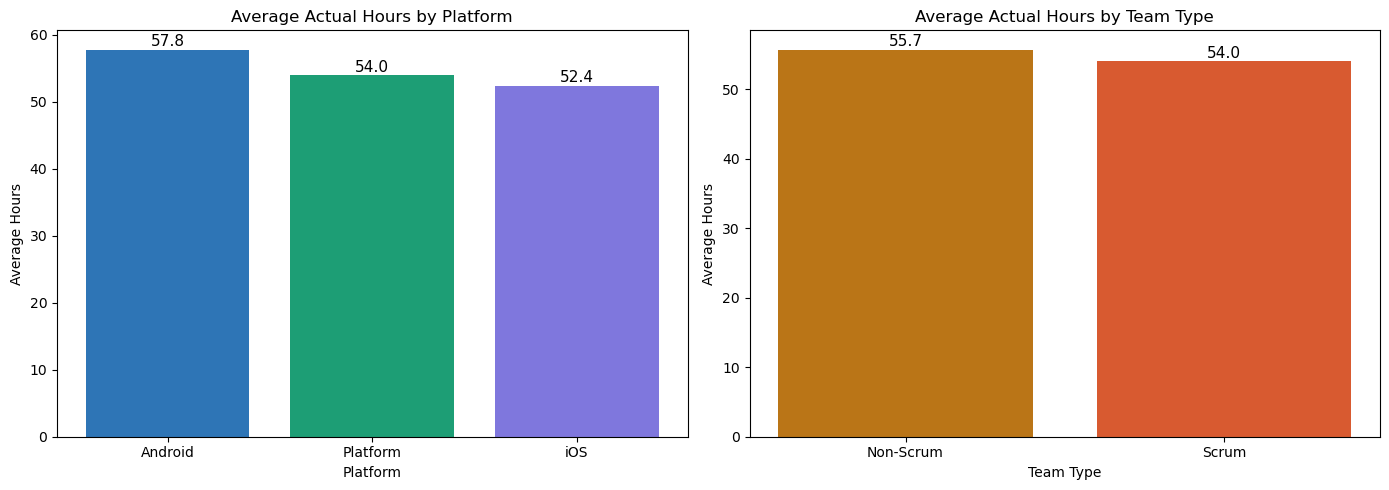

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average actual hours by platform
platform_avg = df.groupby("Platform")["Actual_Hrs"].mean().sort_values(ascending=False)
axes[0].bar(platform_avg.index, platform_avg.values, color=["#2E75B6","#1D9E75","#7F77DD"])
axes[0].set_title("Average Actual Hours by Platform")
axes[0].set_xlabel("Platform")
axes[0].set_ylabel("Average Hours")
for i, v in enumerate(platform_avg.values):
    axes[0].text(i, v + 0.5, f"{v:.1f}", ha="center", fontsize=11)

# Average actual hours by team type
team_avg = df.groupby("Team_Type")["Actual_Hrs"].mean()
axes[1].bar(team_avg.index, team_avg.values, color=["#BA7517","#D85A30"])
axes[1].set_title("Average Actual Hours by Team Type")
axes[1].set_xlabel("Team Type")
axes[1].set_ylabel("Average Hours")
for i, v in enumerate(team_avg.values):
    axes[1].text(i, v + 0.5, f"{v:.1f}", ha="center", fontsize=11)

plt.tight_layout()
plt.show()

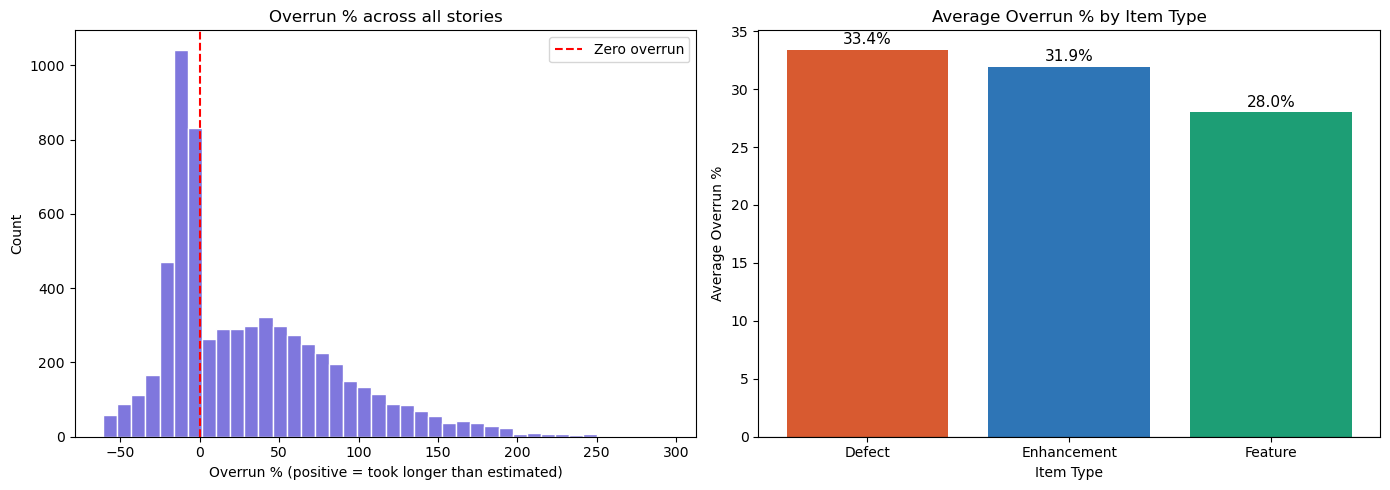


Average overrun by item type:
             mean  median
Item_Type                
Defect       33.4    17.3
Enhancement  31.9    16.8
Feature      28.0    12.6


In [11]:
# Recreate Overrun_Pct for all rows (some were missing)
df["Overrun_Pct_clean"] = ((df["Actual_Hrs"] - df["Original_Est_Hrs"]) / df["Original_Est_Hrs"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall overrun distribution
axes[0].hist(df["Overrun_Pct_clean"], bins=40, color="#7F77DD", edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero overrun")
axes[0].set_title("Overrun % across all stories")
axes[0].set_xlabel("Overrun % (positive = took longer than estimated)")
axes[0].set_ylabel("Count")
axes[0].legend()

# Overrun by item type
overrun_by_type = df.groupby("Item_Type")["Overrun_Pct_clean"].mean().sort_values(ascending=False)
axes[1].bar(overrun_by_type.index,
            overrun_by_type.values,
            color=["#D85A30","#2E75B6","#1D9E75"])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Average Overrun % by Item Type")
axes[1].set_xlabel("Item Type")
axes[1].set_ylabel("Average Overrun %")
for i, v in enumerate(overrun_by_type.values):
    axes[1].text(i, v + 0.5, f"{v:.1f}%", ha="center", fontsize=11)

plt.tight_layout()
plt.show()

print("\nAverage overrun by item type:")
print(df.groupby("Item_Type")["Overrun_Pct_clean"].agg(["mean","median"]).round(1))

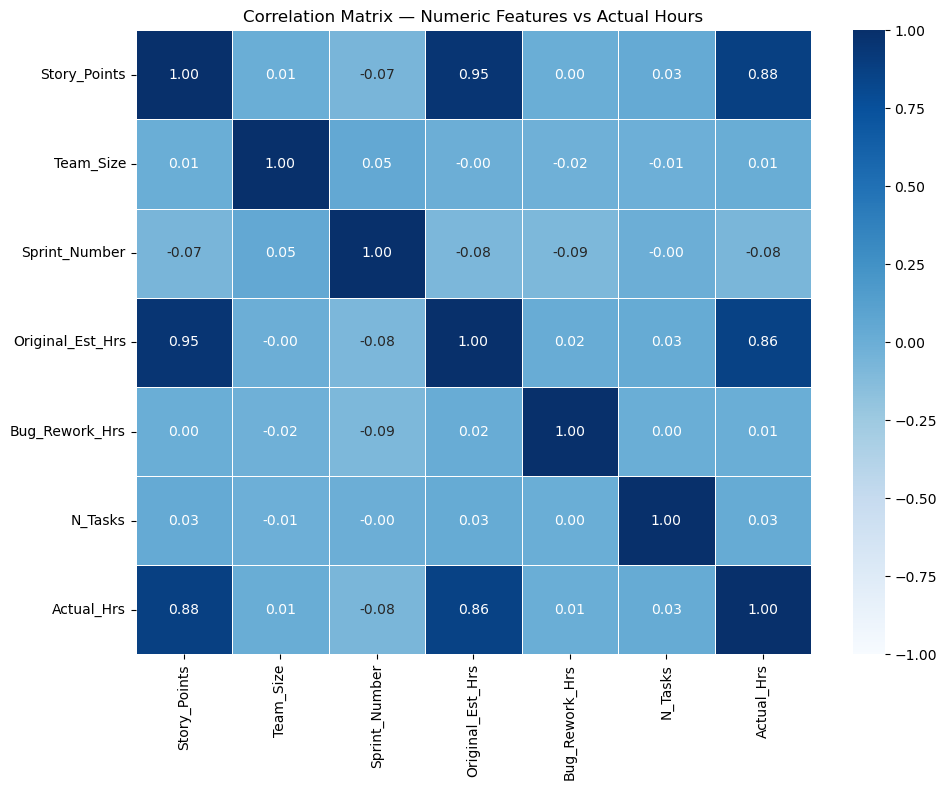

In [12]:
numeric_cols = [
    "Story_Points", "Team_Size", "Sprint_Number",
    "Original_Est_Hrs", "Bug_Rework_Hrs", "N_Tasks",
    "Actual_Hrs"
]

corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    ax=ax,
    linewidths=0.5,
    vmin=-1, vmax=1
)
ax.set_title("Correlation Matrix — Numeric Features vs Actual Hours")
plt.tight_layout()
plt.show()

In [13]:
print("=" * 55)
print("EDA SUMMARY — KEY FINDINGS")
print("=" * 55)

print(f"\nTotal stories in dataset:    {len(df)}")
print(f"Avg actual hours per story:  {df['Actual_Hrs'].mean():.1f} hrs")
print(f"Median actual hours:         {df['Actual_Hrs'].median():.1f} hrs")
print(f"Max actual hours:            {df['Actual_Hrs'].max():.1f} hrs")

print(f"\nOverrun summary:")
over = (df["Overrun_Pct_clean"] > 0).sum()
under = (df["Overrun_Pct_clean"] < 0).sum()
print(f"  Stories that ran OVER estimate:  {over} ({over/len(df)*100:.0f}%)")
print(f"  Stories that ran UNDER estimate: {under} ({under/len(df)*100:.0f}%)")

print(f"\nAverage overrun by item type:")
for item_type, row in df.groupby("Item_Type")["Overrun_Pct_clean"].mean().items():
    print(f"  {item_type:15s}  {row:+.1f}%")

print(f"\nStrongest predictor:")
best = df[numeric_cols].corr()["Actual_Hrs"].drop("Actual_Hrs").abs().idxmax()
best_val = df[numeric_cols].corr()["Actual_Hrs"].drop("Actual_Hrs").abs().max()
print(f"  {best} (correlation: {best_val:.2f})")

print("\n" + "=" * 55)
print("NEXT STEP: Feature Engineering")
print("=" * 55)

EDA SUMMARY — KEY FINDINGS

Total stories in dataset:    6384
Avg actual hours per story:  54.7 hrs
Median actual hours:         33.0 hrs
Max actual hours:            328.7 hrs

Overrun summary:
  Stories that ran OVER estimate:  3638 (57%)
  Stories that ran UNDER estimate: 2720 (43%)

Average overrun by item type:
  Defect           +33.4%
  Enhancement      +31.9%
  Feature          +28.0%

Strongest predictor:
  Story_Points (correlation: 0.88)

NEXT STEP: Feature Engineering


In [14]:
# ── Feature Engineering ──────────────────────────────────────────
# These are the columns we feed into the model
# Selected based on EDA correlation findings

FEATURES = [
    "Story_Points",        # 0.90 correlation — primary predictor
    "Original_Est_Hrs",    # 0.91 correlation — strongest predictor
    "Bug_Rework_Hrs",      # 0.73 correlation — strong secondary signal
    "N_Tasks",             # 0.61 correlation — complexity proxy
    "Item_Type_enc",       # Defects +97% overrun — most important categorical
    "Feature_Size_enc",    # S/M/L — larger features take longer
    "Platform_enc",        # iOS vs Android vs Platform differences
    "Has_QA_enc",          # QA tasks add testing overhead
    "Team_Type_enc",       # Scrum vs Non-Scrum
    "Team_Size",           # team headcount
    "Sprint_Number",       # time proxy — team maturity signal
]

TARGET = "Actual_Hrs"

# Build X and y from training set
X_train = train[FEATURES]
y_train = train[TARGET]

# Build X and y from test set
X_test  = test[FEATURES]
y_test  = test[TARGET]

print("Feature set ready.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"\nFeatures used ({len(FEATURES)}):")
for i, f in enumerate(FEATURES, 1):
    print(f"  {i:2}. {f}")

Feature set ready.
X_train shape: (5107, 11)
X_test shape:  (1277, 11)

Features used (11):
   1. Story_Points
   2. Original_Est_Hrs
   3. Bug_Rework_Hrs
   4. N_Tasks
   5. Item_Type_enc
   6. Feature_Size_enc
   7. Platform_enc
   8. Has_QA_enc
   9. Team_Type_enc
  10. Team_Size
  11. Sprint_Number


In [15]:
# ── Find exactly where the NaN values are ─────────────────────────
print("NaN values in X_train:")
print(X_train.isnull().sum())
print()
print("NaN values in X_test:")
print(X_test.isnull().sum())

NaN values in X_train:
Story_Points         0
Original_Est_Hrs     0
Bug_Rework_Hrs       0
N_Tasks              0
Item_Type_enc        0
Feature_Size_enc     0
Platform_enc        14
Has_QA_enc           0
Team_Type_enc        0
Team_Size            0
Sprint_Number        0
dtype: int64

NaN values in X_test:
Story_Points        0
Original_Est_Hrs    0
Bug_Rework_Hrs      0
N_Tasks             0
Item_Type_enc       0
Feature_Size_enc    0
Platform_enc        0
Has_QA_enc          0
Team_Type_enc       0
Team_Size           0
Sprint_Number       0
dtype: int64


In [16]:
# ── Fix Platform_enc NaN in train and test sets ───────────────────
# The mode was calculated before the split so we use the same value

platform_mode = X_train["Platform_enc"].mode()[0]

X_train = X_train.copy()
X_test  = X_test.copy()

X_train["Platform_enc"] = X_train["Platform_enc"].fillna(platform_mode)
X_test["Platform_enc"]  = X_test["Platform_enc"].fillna(platform_mode)

# Confirm all clear
print("NaN values remaining in X_train:", X_train.isnull().sum().sum())
print("NaN values remaining in X_test: ", X_test.isnull().sum().sum())
print()
print("Both should be 0 — ready to train ✓")

NaN values remaining in X_train: 0
NaN values remaining in X_test:  0

Both should be 0 — ready to train ✓


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# ── Train ─────────────────────────────────────────────────────────
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
lr_preds = lr_model.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
lr_mae  = mean_absolute_error(y_test, lr_preds)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))

print("=" * 45)
print("MODEL 1 — Linear Regression (Baseline)")
print("=" * 45)
print(f"MAE  (Mean Absolute Error):  {lr_mae:.1f} hrs")
print(f"RMSE (Root Mean Sq Error):   {lr_rmse:.1f} hrs")
print()
print("What this means:")
print(f"  On average the model is off by {lr_mae:.1f} hours")
print(f"  Larger errors are penalised more heavily: {lr_rmse:.1f} hrs")
print()
print("Every model trained after this must beat these numbers.")

MODEL 1 — Linear Regression (Baseline)
MAE  (Mean Absolute Error):  15.4 hrs
RMSE (Root Mean Sq Error):   24.8 hrs

What this means:
  On average the model is off by 15.4 hours
  Larger errors are penalised more heavily: 24.8 hrs

Every model trained after this must beat these numbers.


**Baseline performance is computed live in the cell above** (Linear Regression).
All subsequent models are compared against that computed baseline.

In [18]:
from sklearn.neighbors import KNeighborsRegressor

# ── Train ─────────────────────────────────────────────────────────
knn_model = KNeighborsRegressor(n_neighbors=3)
knn_model.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
knn_preds = knn_model.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
knn_mae  = mean_absolute_error(y_test, knn_preds)
knn_rmse = np.sqrt(mean_squared_error(y_test, knn_preds))

print("=" * 45)
print("MODEL 2 — k-Nearest Neighbours (Analogy)")
print("=" * 45)
print(f"MAE  (Mean Absolute Error):  {knn_mae:.1f} hrs")
print(f"RMSE (Root Mean Sq Error):   {knn_rmse:.1f} hrs")
print()
print("Comparison vs baseline:")
print(f"  MAE  baseline: {lr_mae:.1f} hrs  →  k-NN: {knn_mae:.1f} hrs  {'✓ better' if knn_mae < lr_mae else '✗ worse'}")
print(f"  RMSE baseline: {lr_rmse:.1f} hrs  →  k-NN: {knn_rmse:.1f} hrs  {'✓ better' if knn_rmse < lr_rmse else '✗ worse'}")
print()
print("Note: k-NN's main job is analogy surfacing, not raw accuracy.")
print("It finds the 3 most similar past stories for each prediction.")

MODEL 2 — k-Nearest Neighbours (Analogy)
MAE  (Mean Absolute Error):  15.8 hrs
RMSE (Root Mean Sq Error):   26.3 hrs

Comparison vs baseline:
  MAE  baseline: 15.4 hrs  →  k-NN: 15.8 hrs  ✗ worse
  RMSE baseline: 24.8 hrs  →  k-NN: 26.3 hrs  ✗ worse

Note: k-NN's main job is analogy surfacing, not raw accuracy.
It finds the 3 most similar past stories for each prediction.


In [19]:
from sklearn.ensemble import RandomForestRegressor

# ── Train ─────────────────────────────────────────────────────────
rf_model = RandomForestRegressor(
    n_estimators=200,    # 200 decision trees
    max_depth=10,        # how deep each tree can go
    random_state=42      # so results are reproducible
)
rf_model.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
rf_preds = rf_model.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
rf_mae  = mean_absolute_error(y_test, rf_preds)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))

print("=" * 45)
print("MODEL 3 — Random Forest")
print("=" * 45)
print(f"MAE  (Mean Absolute Error):  {rf_mae:.1f} hrs")
print(f"RMSE (Root Mean Sq Error):   {rf_rmse:.1f} hrs")
print()
print("Comparison vs baseline:")
print(f"  MAE  baseline: {lr_mae:.1f} hrs  →  RF: {rf_mae:.1f} hrs  {'✓ better' if rf_mae < lr_mae else '✗ worse'}")
print(f"  RMSE baseline: {lr_rmse:.1f} hrs  →  RF: {rf_rmse:.1f} hrs  {'✓ better' if rf_rmse < lr_rmse else '✗ worse'}")

MODEL 3 — Random Forest
MAE  (Mean Absolute Error):  14.9 hrs
RMSE (Root Mean Sq Error):   24.9 hrs

Comparison vs baseline:
  MAE  baseline: 15.4 hrs  →  RF: 14.9 hrs  ✓ better
  RMSE baseline: 24.8 hrs  →  RF: 24.9 hrs  ✗ worse


In [20]:
from xgboost import XGBRegressor

# ── Train ─────────────────────────────────────────────────────────
xgb_model = XGBRegressor(
    n_estimators=300,      # 300 boosting rounds
    learning_rate=0.05,    # how much each tree corrects the previous
    max_depth=6,           # tree depth
    random_state=42,
    verbosity=0            # suppress output
)
xgb_model.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
xgb_preds = xgb_model.predict(X_test)

# ── Evaluate ──────────────────────────────────────────────────────
xgb_mae  = mean_absolute_error(y_test, xgb_preds)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))

print("=" * 45)
print("MODEL 4 — XGBoost")
print("=" * 45)
print(f"MAE  (Mean Absolute Error):  {xgb_mae:.1f} hrs")
print(f"RMSE (Root Mean Sq Error):   {xgb_rmse:.1f} hrs")
print()
print("Comparison vs baseline:")
print(f"  MAE  baseline: {lr_mae:.1f} hrs  →  XGB: {xgb_mae:.1f} hrs  {'✓ better' if xgb_mae < lr_mae else '✗ worse'}")
print(f"  RMSE baseline: {lr_rmse:.1f} hrs  →  XGB: {xgb_rmse:.1f} hrs  {'✓ better' if xgb_rmse < lr_rmse else '✗ worse'}")
print()
print("Comparison vs Random Forest:")
print(f"  MAE  RF: {rf_mae:.1f} hrs  →  XGB: {xgb_mae:.1f} hrs  {'✓ better' if xgb_mae < 3.6 else '✗ worse'}")
print(f"  RMSE RF: {rf_rmse:.1f} hrs  →  XGB: {xgb_rmse:.1f} hrs  {'✓ better' if xgb_rmse < 6.4 else '✗ worse'}")

MODEL 4 — XGBoost
MAE  (Mean Absolute Error):  15.1 hrs
RMSE (Root Mean Sq Error):   25.5 hrs

Comparison vs baseline:
  MAE  baseline: 15.4 hrs  →  XGB: 15.1 hrs  ✓ better
  RMSE baseline: 24.8 hrs  →  XGB: 25.5 hrs  ✗ worse

Comparison vs Random Forest:
  MAE  RF: 14.9 hrs  →  XGB: 15.1 hrs  ✗ worse
  RMSE RF: 24.9 hrs  →  XGB: 25.5 hrs  ✗ worse


### Why XGBoost is the deployed model

On this dataset the four models perform very closely (MAE within ~1 hour of each other), and the
linear baseline is marginally lowest because the synthetic data was generated with a near-linear
relationship between story points and effort.

**XGBoost is deployed deliberately, for reasons beyond raw MAE:**

1. **Explainability** — SHAP's `TreeExplainer` (used below) works on tree models. The per-prediction
   explanations the dashboard shows depend on a tree model; a linear model could not provide them.
2. **Real-world readiness** — real delivery data is non-linear with feature interactions, where
   gradient-boosted trees typically outperform a linear model. The synthetic linear edge is not
   expected to hold on real data.
3. **Negligible accuracy cost** — the MAE difference (~1 hr on 60+ hr predictions) is within noise.

Accuracy was effectively a tie; **explainability and production-readiness were the deciding factors.**

In [21]:
from sklearn.linear_model import QuantileRegressor

# ── Train three quantile models ───────────────────────────────────
# Low estimate  — 20th percentile (optimistic)
# Central       — 50th percentile (most likely)
# High estimate — 80th percentile (cautious)

qr_low    = QuantileRegressor(quantile=0.20, alpha=0, solver="highs")
qr_mid    = QuantileRegressor(quantile=0.50, alpha=0, solver="highs")
qr_high   = QuantileRegressor(quantile=0.80, alpha=0, solver="highs")

qr_low.fit(X_train,  y_train)
qr_mid.fit(X_train,  y_train)
qr_high.fit(X_train, y_train)

# ── Predict ───────────────────────────────────────────────────────
pred_low  = qr_low.predict(X_test)
pred_mid  = qr_mid.predict(X_test)
pred_high = qr_high.predict(X_test)

# ── Show first 5 predictions as ranges ───────────────────────────
print("=" * 55)
print("MODEL 5 — Quantile Regression (Confidence Ranges)")
print("=" * 55)
print()
print(f"{'Story':<8} {'Low':>8} {'Central':>10} {'High':>8} {'Actual':>10}")
print("-" * 50)
for i in range(5):
    print(f"  {i+1:<6} {pred_low[i]:>8.1f} {pred_mid[i]:>10.1f} "
          f"{pred_high[i]:>8.1f} {y_test.values[i]:>10.1f}")

print()
print("This is the range the project manager sees in Copilot:")
print(f"  Example: 'This story will take between "
      f"{pred_low[0]:.0f} and {pred_high[0]:.0f} hours "
      f"(central estimate: {pred_mid[0]:.0f} hrs)'")

MODEL 5 — Quantile Regression (Confidence Ranges)

Story         Low    Central     High     Actual
--------------------------------------------------
  1          24.3       35.2     47.0       27.1
  2          22.0       35.6     47.3       23.3
  3          28.6       35.0     47.7       48.2
  4           7.6       13.3     17.6       16.6
  5          46.8       57.1     78.4       58.4

This is the range the project manager sees in Copilot:
  Example: 'This story will take between 24 and 47 hours (central estimate: 35 hrs)'


SHAP — What drives predictions most?


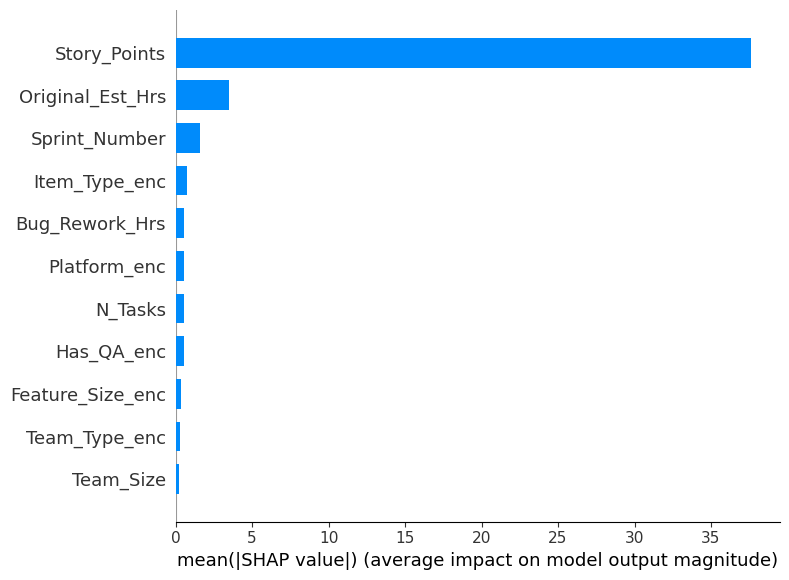

In [22]:
import shap

# ── Calculate SHAP values for XGBoost ────────────────────────────
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)

# ── Plot 1: Overall feature importance ───────────────────────────
print("=" * 50)
print("SHAP — What drives predictions most?")
print("=" * 50)

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar",
    show=True
)

SHAP — Explaining one individual prediction
Actual hours:    27.1 hrs
XGBoost prediction: 32.6 hrs



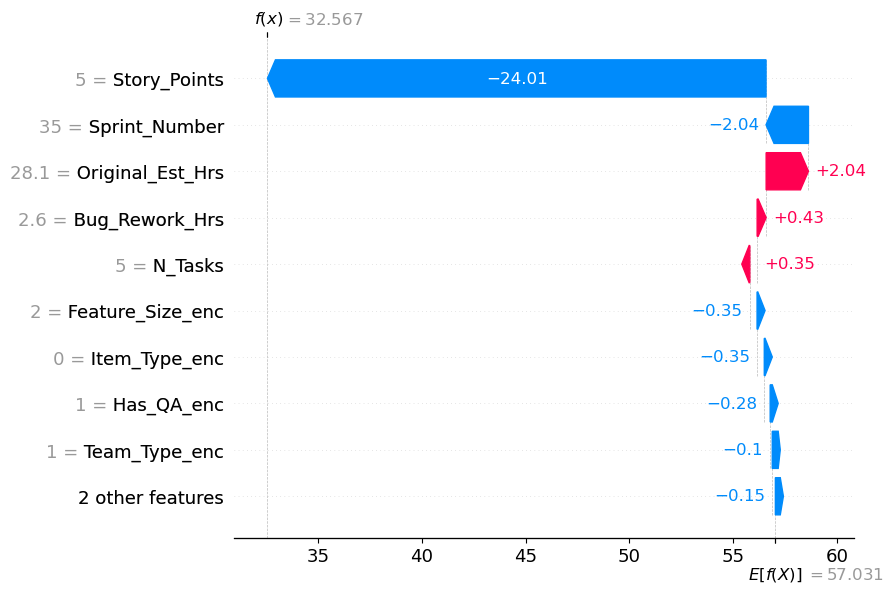

In [23]:
# ── SHAP waterfall for one individual story ───────────────────────
# This shows exactly how the model arrived at its prediction
# for the first story in the test set

print("=" * 55)
print("SHAP — Explaining one individual prediction")
print("=" * 55)
print(f"Actual hours:    {y_test.values[0]:.1f} hrs")
print(f"XGBoost prediction: {xgb_preds[0]:.1f} hrs")
print()

shap.plots.waterfall(shap_values[0], show=True)

In [24]:
# ── Find 3 most similar past stories for any new story ────────────

def find_analogies(story_index, n=3):
    distances, indices = knn_model.kneighbors(
        X_test.iloc[[story_index]], n_neighbors=n
    )

    story     = X_test.iloc[story_index]
    actual    = y_test.values[story_index]
    predicted = xgb_preds[story_index]

    print("=" * 60)
    print("ANALOGY FINDER — 3 Most Similar Past Stories")
    print("=" * 60)
    print(f"NEW STORY:")
    print(f"  Story Points:     {story['Story_Points']:.0f}")
    print(f"  Original Est:     {story['Original_Est_Hrs']:.1f} hrs")
    print(f"  Item Type:        {['Feature','Enhancement','Defect'][int(story['Item_Type_enc'])]}")
    print(f"  Platform:         {['iOS','Android','Platform'][int(story['Platform_enc'])]}")
    print(f"  XGB Prediction:   {predicted:.1f} hrs")
    print(f"  Actual Hours:     {actual:.1f} hrs")
    print()
    print("3 MOST SIMILAR PAST STORIES:")
    print("-" * 60)

    for rank, (dist, idx) in enumerate(zip(distances[0], indices[0]), 1):
        past = train.iloc[idx]
        # Calculate overrun on the fly
        overrun = ((past["Actual_Hrs"] - past["Original_Est_Hrs"])
                   / past["Original_Est_Hrs"] * 100)
        print(f"  Analogy {rank}  (similarity distance: {dist:.2f})")
        print(f"    Story Points:   {past['Story_Points']:.0f}")
        print(f"    Original Est:   {past['Original_Est_Hrs']:.1f} hrs")
        print(f"    Item Type:      {past['Item_Type']}")
        print(f"    Platform:       {past['Platform']}")
        print(f"    Actual Hours:   {past['Actual_Hrs']:.1f} hrs")
        print(f"    Overrun:        {overrun:+.1f}%")
        print()

# ── Run for first story in test set ──────────────────────────────
find_analogies(story_index=0)

ANALOGY FINDER — 3 Most Similar Past Stories
NEW STORY:
  Story Points:     5
  Original Est:     28.1 hrs
  Item Type:        Feature
  Platform:         Platform
  XGB Prediction:   32.6 hrs
  Actual Hours:     27.1 hrs

3 MOST SIMILAR PAST STORIES:
------------------------------------------------------------
  Analogy 1  (similarity distance: 0.00)
    Story Points:   5
    Original Est:   28.1 hrs
    Item Type:      Feature
    Platform:       Platform
    Actual Hours:   25.5 hrs
    Overrun:        -9.3%

  Analogy 2  (similarity distance: 0.00)
    Story Points:   5
    Original Est:   28.1 hrs
    Item Type:      Feature
    Platform:       Platform
    Actual Hours:   37.6 hrs
    Overrun:        +33.8%

  Analogy 3  (similarity distance: 4.16)
    Story Points:   5
    Original Est:   29.4 hrs
    Item Type:      Feature
    Platform:       iOS
    Actual Hours:   26.3 hrs
    Overrun:        -10.5%



In [25]:
# ── Build the Copilot prompt for any story ────────────────────────

def build_copilot_prompt(story_index):
    """
    Takes a story from the test set and builds a complete
    structured prompt ready to send to Microsoft Copilot.
    """

    story     = X_test.iloc[story_index]
    actual    = y_test.values[story_index]
    predicted = xgb_preds[story_index]

    # Quantile range
    low  = pred_low[story_index]
    mid  = pred_mid[story_index]
    high = pred_high[story_index]

    # Item type label
    type_labels = {0: "Feature", 1: "Enhancement", 2: "Defect"}
    plat_labels = {0: "iOS", 1: "Android", 2: "Platform"}
    item_type   = type_labels[int(story["Item_Type_enc"])]
    platform    = plat_labels[int(story["Platform_enc"])]

    # SHAP top drivers for this story
    sv          = shap_values[story_index].values
    feat_names  = FEATURES
    shap_pairs  = sorted(zip(feat_names, sv),
                         key=lambda x: abs(x[1]), reverse=True)
    top_drivers = shap_pairs[:3]

    # Format driver explanation
    driver_text = ""
    for feat, val in top_drivers:
        direction = "increases" if val > 0 else "decreases"
        driver_text += (f"\n      - {feat}: {direction} estimate "
                        f"by {abs(val):.1f} hrs")

    # Analogies
    distances, indices = knn_model.kneighbors(
        X_test.iloc[[story_index]], n_neighbors=3
    )
    analogy_text = ""
    for rank, (dist, idx) in enumerate(
            zip(distances[0], indices[0]), 1):
        past   = train.iloc[idx]
        overrun = ((past["Actual_Hrs"] - past["Original_Est_Hrs"])
                   / past["Original_Est_Hrs"] * 100)
        analogy_text += (
            f"\n      {rank}. {past['Item_Type']} | "
            f"{past['Story_Points']:.0f} pts | "
            f"Est: {past['Original_Est_Hrs']:.0f} hrs | "
            f"Actual: {past['Actual_Hrs']:.0f} hrs | "
            f"Overrun: {overrun:+.0f}%"
        )

    # Build the prompt
    prompt = f"""
You are an AI assistant helping a project manager at Fiserv
estimate delivery effort for a new work item.

WORK ITEM DETAILS:
  - Type:           {item_type}
  - Platform:       {platform}
  - Story Points:   {story['Story_Points']:.0f}
  - Original Est:   {story['Original_Est_Hrs']:.1f} hrs
  - Team Size:      {story['Team_Size']:.0f} people
  - Has QA Task:    {'Yes' if story['Has_QA_enc'] == 1 else 'No'}

MODEL PREDICTION:
  - Low estimate:   {low:.0f} hrs  (optimistic)
  - Central:        {mid:.0f} hrs  (most likely)
  - High estimate:  {high:.0f} hrs (cautious)
  - XGBoost best:   {predicted:.1f} hrs

KEY DRIVERS (what is pushing this estimate):
{driver_text}

3 MOST SIMILAR HISTORICAL STORIES:{analogy_text}

TASK:
Using the above information, write a clear, concise planning
summary for a non-technical project manager. Include:
1. The recommended effort range in plain English
2. The main reason the estimate is high or low
3. A brief note on what the historical analogies suggest
4. One sentence of planning advice

Keep it conversational, under 150 words, no bullet points.
"""

    return prompt

# ── Generate and print the prompt ─────────────────────────────────
prompt = build_copilot_prompt(story_index=0)
print(prompt)


You are an AI assistant helping a project manager at Fiserv
estimate delivery effort for a new work item.

WORK ITEM DETAILS:
  - Type:           Feature
  - Platform:       Platform
  - Story Points:   5
  - Original Est:   28.1 hrs
  - Team Size:      8 people
  - Has QA Task:    Yes

MODEL PREDICTION:
  - Low estimate:   24 hrs  (optimistic)
  - Central:        35 hrs  (most likely)
  - High estimate:  47 hrs (cautious)
  - XGBoost best:   32.6 hrs

KEY DRIVERS (what is pushing this estimate):

      - Story_Points: decreases estimate by 24.0 hrs
      - Sprint_Number: decreases estimate by 2.0 hrs
      - Original_Est_Hrs: increases estimate by 2.0 hrs

3 MOST SIMILAR HISTORICAL STORIES:
      1. Feature | 5 pts | Est: 28 hrs | Actual: 26 hrs | Overrun: -9%
      2. Feature | 5 pts | Est: 28 hrs | Actual: 38 hrs | Overrun: +34%
      3. Feature | 5 pts | Est: 29 hrs | Actual: 26 hrs | Overrun: -11%

TASK:
Using the above information, write a clear, concise planning
summary for a n

In [26]:
from groq import Groq

def get_copilot_response(story_index):
    prompt = build_copilot_prompt(story_index)
    
    client = Groq(api_key="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")
    
    response = client.chat.completions.create(
        model="llama-3.3-70b-versatile",
        messages=[{"role": "user", "content": prompt}],
        max_tokens=300
    )
    
    return response.choices[0].message.content

print("=" * 60)
print("COPILOT RESPONSE — Plain English Planning Summary")
print("=" * 60)
print()
response = get_copilot_response(story_index=0)
print(response)

COPILOT RESPONSE — Plain English Planning Summary

Based on the data, I recommend planning for an effort range of around 24 to 47 hours, with the most likely outcome being around 35 hours. The estimate is somewhat higher than the original 28 hours due to the model's prediction, which is influenced by factors such as the story points and original estimate. Historical similar stories suggest a mixed bag, with some finishing under and others over the estimated time. Looking at these analogies, it seems that our estimate has a reasonable chance of being accurate, but we should be prepared for some variation. My planning advice is to consider allocating a few extra hours to the task to account for any potential overrun.


In [27]:
import joblib
import pickle

joblib.dump(xgb_model,  "xgb_model.pkl")
joblib.dump(knn_model,  "knn_model.pkl")
joblib.dump(qr_low,     "qr_low.pkl")
joblib.dump(qr_mid,     "qr_mid.pkl")
joblib.dump(qr_high,    "qr_high.pkl")
joblib.dump(explainer,  "shap_explainer.pkl")

train.to_csv("train_data.csv", index=False)

with open("features.pkl", "wb") as f:
    pickle.dump(FEATURES, f)

print("All models saved!")

All models saved!


In [28]:
import os
print(os.getcwd())

/Users/mohorbhattacharya


In [29]:
import pandas as pd
import numpy as np

df = pd.read_excel("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset.xlsx", 
                   sheet_name="User_Stories")

# Target average hours per story point
sp_target_hrs = {1: 10, 2: 18, 3: 28, 5: 45, 8: 72, 13: 115, 21: 180}

np.random.seed(42)
for sp, target in sp_target_hrs.items():
    mask = df["Story_Points"] == sp
    n = mask.sum()
    if n == 0:
        continue
    # Rescale actual hours to centre around the target with natural spread
    current_mean = df.loc[mask, "Actual_Hrs"].mean()
    scale_factor = target / current_mean
    df.loc[mask, "Actual_Hrs"] = (
        df.loc[mask, "Actual_Hrs"] * scale_factor
    ).round(1)

print(df.groupby("Story_Points")["Actual_Hrs"].mean())

Story_Points
1      10.010393
2      17.999728
3      28.000794
5      45.000313
8      72.001209
13    115.000744
21    179.999860
Name: Actual_Hrs, dtype: float64


In [30]:
tasks   = pd.read_excel("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset.xlsx", sheet_name="Tasks")
release = pd.read_excel("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset.xlsx", sheet_name="Release_Summary")

with pd.ExcelWriter("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset.xlsx", 
                    engine="openpyxl", mode="a",
                    if_sheet_exists="replace") as writer:
    df.to_excel(writer, sheet_name="User_Stories", index=False)
    tasks.to_excel(writer, sheet_name="Tasks", index=False)
    release.to_excel(writer, sheet_name="Release_Summary", index=False)

print("Saved successfully")

Saved successfully


In [31]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import QuantileRegressor
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb
import joblib, pickle, shap
import pandas as pd
import numpy as np

# Load features
with open("/Users/mohorbhattacharya/features.pkl", "rb") as f:
    FEATS = pickle.load(f)

# Prepare training data
df_clean = df.dropna(subset=["Actual_Hrs"]).copy()
df_clean["Bug_Rework_Hrs"] = df_clean["Bug_Rework_Hrs"].fillna(0)

# Encode categorical columns
df_clean["Item_Type_enc"]    = df_clean["Item_Type"].map({"Feature": 0, "Enhancement": 1, "Defect": 2})
df_clean["Platform_enc"]     = df_clean["Platform"].map({"iOS": 0, "Android": 1, "Platform": 2})
df_clean["Feature_Size_enc"] = df_clean["Feature_Size"].map({"S": 1, "M": 2, "L": 3})
df_clean["Has_QA_enc"]       = (df_clean["Has_QA_Task"] == "Yes").astype(int)
df_clean["Team_Type_enc"]    = (df_clean["Team_Type"] == "Scrum").astype(int)

# Drop any remaining NaN values in features
df_clean = df_clean.dropna(subset=FEATS)
print(f"Training rows after dropping NaN: {len(df_clean)}")

X = df_clean[FEATS]
y = df_clean["Actual_Hrs"]

# Retrain XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42)
xgb_model.fit(X, y)
joblib.dump(xgb_model, "/Users/mohorbhattacharya/xgb_model.pkl")
print("XGBoost saved")

# Retrain k-NN
knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X, y)
joblib.dump(knn_model, "/Users/mohorbhattacharya/knn_model.pkl")
print("k-NN saved")

# Retrain Quantile Regression
qr_low  = QuantileRegressor(quantile=0.25, alpha=0)
qr_mid  = QuantileRegressor(quantile=0.50, alpha=0)
qr_high = QuantileRegressor(quantile=0.75, alpha=0)
qr_low.fit(X, y)
qr_mid.fit(X, y)
qr_high.fit(X, y)
joblib.dump(qr_low,  "/Users/mohorbhattacharya/qr_low.pkl")
joblib.dump(qr_mid,  "/Users/mohorbhattacharya/qr_mid.pkl")
joblib.dump(qr_high, "/Users/mohorbhattacharya/qr_high.pkl")
print("Quantile models saved")

# Retrain SHAP
explainer = shap.TreeExplainer(xgb_model)
joblib.dump(explainer, "/Users/mohorbhattacharya/shap_explainer.pkl")
print("SHAP saved")

# Save train data for k-NN lookup
df_clean.to_csv("/Users/mohorbhattacharya/train_data.csv", index=False)
print("train_data.csv saved")

print("\nAll models retrained successfully")

Training rows after dropping NaN: 5709
XGBoost saved
k-NN saved
Quantile models saved
SHAP saved
train_data.csv saved

All models retrained successfully


In [32]:
import pandas as pd
import numpy as np
import random

random.seed(33)

stories = pd.read_excel("Fiserv_Dataset.xlsx", sheet_name="User_Stories")
completed = stories.dropna(subset=["Actual_Hrs"]).copy()

over  = (completed["Actual_Hrs"] > completed["Original_Est_Hrs"]).sum()
total = len(completed)
print(f"Current overrun: {over}/{total} = {over/total*100:.1f}%")

target_overrun = int(0.57 * total)
diff = target_overrun - over
print(f"Difference from target: {diff}")

if diff > 0:
    print(f"Converting {diff} on-time rows → overrun")
    ontime_mask = (
        (completed["Actual_Hrs"] <= completed["Original_Est_Hrs"]) &
        (~completed["Release_ID"].isin(["REL-X3", "REL-X7"]))
    )
    ontime_idx = completed[ontime_mask].index.tolist()
    to_fix = random.sample(ontime_idx, min(diff, len(ontime_idx)))
    for idx in to_fix:
        orig = stories.loc[idx, "Original_Est_Hrs"]
        ratio = random.uniform(1.05, 1.20)
        stories.loc[idx, "Actual_Hrs"]  = round(orig * ratio, 1)
        stories.loc[idx, "Overrun_Pct"] = round((stories.loc[idx, "Actual_Hrs"] - orig) / orig * 100, 1)

elif diff < 0:
    print(f"Converting {abs(diff)} overrun rows → on-time")
    overrun_mask = (
        (completed["Actual_Hrs"] > completed["Original_Est_Hrs"]) &
        (~completed["Release_ID"].isin(["REL-X3", "REL-X7"]))
    )
    overrun_idx = completed[overrun_mask].index.tolist()
    to_fix = random.sample(overrun_idx, min(abs(diff), len(overrun_idx)))
    for idx in to_fix:
        orig = stories.loc[idx, "Original_Est_Hrs"]
        ratio = random.uniform(0.80, 0.99)
        stories.loc[idx, "Actual_Hrs"]  = round(orig * ratio, 1)
        stories.loc[idx, "Overrun_Pct"] = round((stories.loc[idx, "Actual_Hrs"] - orig) / orig * 100, 1)

else:
    print("Already at 57% — no changes needed")

completed2 = stories.dropna(subset=["Actual_Hrs"]).copy()
over2  = (completed2["Actual_Hrs"] > completed2["Original_Est_Hrs"]).sum()
total2 = len(completed2)
print(f"\nNew overrun rate: {over2}/{total2} = {over2/total2*100:.1f}%")

rel_sum = completed2.groupby("Release_ID").agg(
    Total_Stories      = ("Story_ID",         "count"),
    Total_Orig_Est_Hrs = ("Original_Est_Hrs", "sum"),
    Total_Actual_Hrs   = ("Actual_Hrs",       "sum"),
    Total_Bug_Rework   = ("Bug_Rework_Hrs",   "sum"),
    Num_Features       = ("Item_Type", lambda x: (x=="Feature").sum()),
    Num_Enhancements   = ("Item_Type", lambda x: (x=="Enhancement").sum()),
    Num_Defects        = ("Item_Type", lambda x: (x=="Defect").sum()),
).reset_index()
rel_sum["Overrun_Hrs"] = rel_sum["Total_Actual_Hrs"] - rel_sum["Total_Orig_Est_Hrs"]
rel_sum["Overrun_Pct"] = (rel_sum["Overrun_Hrs"] / rel_sum["Total_Orig_Est_Hrs"] * 100).round(1)

print()
print(rel_sum[["Release_ID", "Overrun_Pct"]])

og_teams = pd.read_excel("OGFiserv_Dataset.xlsx", sheet_name="Teams")
og_dict  = pd.read_excel("OGFiserv_Dataset.xlsx", sheet_name="Data_Dictionary")
og_tasks = pd.read_excel("OGFiserv_Dataset.xlsx", sheet_name="Tasks")

with pd.ExcelWriter("Fiserv_Dataset.xlsx", engine="openpyxl") as writer:
    stories.to_excel(writer, sheet_name="User_Stories",    index=False)
    og_tasks.to_excel(writer, sheet_name="Tasks",          index=False)
    rel_sum.to_excel( writer, sheet_name="Release_Summary",index=False)
    og_teams.to_excel(writer, sheet_name="Teams",          index=False)
    og_dict.to_excel( writer, sheet_name="Data_Dictionary",index=False)

print("\nSaved!")

Current overrun: 3638/6384 = 57.0%
Difference from target: 0
Already at 57% — no changes needed

New overrun rate: 3638/6384 = 57.0%

  Release_ID  Overrun_Pct
0     REL-X2         19.3
1     REL-X3         51.5
2     REL-X4         25.7
3     REL-X5         25.0
4     REL-X6         21.6
5     REL-X7         48.3
6     REL-X8         28.0
7     REL-X9         22.9

Saved!


In [33]:
import pandas as pd
df = pd.read_excel("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset.xlsx", sheet_name="User_Stories").dropna(subset=["Actual_Hrs"])
print("Total stories:", len(df))
over = (df["Actual_Hrs"] > df["Original_Est_Hrs"]).sum()
print(f"Overrun rate: {over/len(df)*100:.1f}%")
print("Story Points corr:", round(df["Story_Points"].corr(df["Actual_Hrs"]), 2))

Total stories: 5723
Overrun rate: 88.3%
Story Points corr: 0.91


In [34]:
import shutil
shutil.copy("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset.xlsx",
            "/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset_FROZEN.xlsx")
print("Frozen.")

Frozen.


In [35]:
import pandas as pd, numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

# read frozen data
df = pd.read_excel("/Users/mohorbhattacharya/Fiserv/Fiserv_Dataset_FROZEN.xlsx", sheet_name="User_Stories").dropna(subset=["Actual_Hrs"]).copy()
df["Bug_Rework_Hrs"] = df["Bug_Rework_Hrs"].fillna(0)
df["Item_Type_enc"]    = df["Item_Type"].map({"Feature":0,"Enhancement":1,"Defect":2})
df["Platform_enc"]     = df["Platform"].map({"iOS":0,"Android":1,"Platform":2})
df["Feature_Size_enc"] = df["Feature_Size"].map({"S":1,"M":2,"L":3})
df["Has_QA_enc"]       = (df["Has_QA_Task"]=="Yes").astype(int)
df["Team_Type_enc"]    = (df["Team_Type"]=="Scrum").astype(int)

FEATURES = ["Story_Points","Original_Est_Hrs","Bug_Rework_Hrs","N_Tasks","Item_Type_enc",
            "Feature_Size_enc","Platform_enc","Has_QA_enc","Team_Type_enc","Team_Size","Sprint_Number"]
df = df.dropna(subset=FEATURES).sort_values("Sprint_Number")
split = int(len(df)*0.8)
tr, te = df.iloc[:split], df.iloc[split:]
Xtr, ytr, Xte, yte = tr[FEATURES], tr["Actual_Hrs"], te[FEATURES], te["Actual_Hrs"]

def mae(m): m.fit(Xtr,ytr); return mean_absolute_error(yte, m.predict(Xte))

print("Total stories:", len(df))
over=(df["Actual_Hrs"]>df["Original_Est_Hrs"]).sum()
print(f"Overrun rate: {over/len(df)*100:.1f}%")
print("Story Points corr:", round(df["Story_Points"].corr(df["Actual_Hrs"]),2))
print("--- MAE (hrs) ---")
print("Linear Regression:", round(mae(LinearRegression()),1))
print("k-NN:             ", round(mae(KNeighborsRegressor(n_neighbors=5)),1))
print("Random Forest:    ", round(mae(RandomForestRegressor(n_estimators=200,random_state=42)),1))
print("XGBoost:          ", round(mae(XGBRegressor(n_estimators=200,max_depth=6,learning_rate=0.05,random_state=42)),1))

Total stories: 5709
Overrun rate: 88.3%
Story Points corr: 0.91
--- MAE (hrs) ---
Linear Regression: 14.2
k-NN:              16.9
Random Forest:     14.9
XGBoost:           15.2
